<!--

    Gaia Data Processing and Analysis Consortium (DPAC) 
    Co-ordination Unit 9 Work Package 930
    
    (c) 2005-2025 Gaia DPAC
    
    This program is free software: you can redistribute it and/or modify
    it under the terms of the GNU General Public License as published by
    the Free Software Foundation, either version 3 of the License, or
    (at your option) any later version.

    This program is distributed in the hope that it will be useful,
    but WITHOUT ANY WARRANTY; without even the implied warranty of
    MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
    GNU General Public License for more details.

    You should have received a copy of the GNU General Public License
    along with this program.  If not, see <https://www.gnu.org/licenses/>.
    -->

# Using ML to define an astrometrically clean sample of stars

Follows the Gaia EDR3 performance verification "The Gaia Catalogue of Nearby Stars" (Smart et al. 2021) in classifying astrometric solutions as good or bad via supervised ML. Employs a Random Forrest classifier plus appropriately defined training sets - see https://arxiv.org/abs/2012.02061 for further details. The work flow implemented here follows closely that described in Section 2, "GCNS Generation" (GCNS = Gaia Catalogue of Nearby Stars) and is designed to clean up a 100pc (= nearby) sample.

   

In [1]:
# Import the spark config
#from astroflow_spark_gaia import spark
from spark_setup import SparkSetup
from setup_data_gaia_dr3 import SetupDataGaiaDR3
spark_setup = SparkSetup(pods=10, cpu=20, mem=30, data_setup=SetupDataGaiaDR3)
spark = spark_setup.get_spark_session()

# this is the set of astrometric features to be used. In reality several iterations of this workflow might be required with an expanded set, and some figure-of-merit,
# e.g. Gini index, would be used to select those most important to the RF classification - cf. Table A.1 in the GCNS paper.
astrometric_features = [
    'parallax_error', 
    'parallax_over_error',
    'astrometric_sigma5d_max',
    'pmra_error',
    'pmdec_error',
    'astrometric_excess_noise',
    'ipd_gof_harmonic_amplitude',
    'ruwe', 
    'visibility_periods_used',
    'pmdec',
    'pmra',
    'ipd_frac_odd_win',
    'ipd_frac_multi_peak',
    'astrometric_gof_al',
    'parallax_pmdec_corr',
    'astrometric_excess_noise_sig'
]
# ... the last two are included to cross check against the Gini index results presented in the paper.

# quick mode: set an additional predicate filter on random_index here to limit to 10% (or 1%: change 10 to 100) sampling etc:
quick_filter = ''# AND MOD(random_index, 10) = 0'
# ... to switch this off, simply specify an empty string. But to avoid overloading matplotlib when visualising results, keep this one:
quick_plot_filter = ' AND MOD(random_index, 25) = 0'

# reformat the above attribute list into an SQL comma-separated select string
features_select_string = ('%s, '*(len(astrometric_features) - 1) + '%s ')%tuple(astrometric_features)
#print (features_select_string)

# Confirmed by Luis Sarro, personal communication: actually we train on ABS(parallax_over_error), see e.g. GCNS paper Figure A.5
features_select_string = features_select_string.replace('parallax_over_error','ABS(parallax_over_error) AS parallax_over_error')

# photometric consistency predicate - e.g. Evans et al. (2018), Babusiaux et al. (2018) for DR2:
#photometric_consistency_filter = ' AND phot_bp_rp_excess_factor BETWEEN 1.0 + (0.03 * POW(bp_rp, 2.0)) AND 1.3 + (0.06 * POW(bp_rp, 2.0))'
# Riello et al. (2020) for EDR3: fgbp_grp defined by Equation 6 and coefficients in Table 2; sig_cstarg defined by Equation 18:
photometric_consistency_indicators = \
    '1.15436 + 0.033772*bp_rp + 0.032277*bp_rp*bp_rp AS fgbp_grp_0p5, ' + \
    '1.162004 + 0.011464*bp_rp + 0.049255*bp_rp*bp_rp -0.005879*bp_rp*bp_rp*bp_rp AS fgbp_grp_0p5_4p0, ' + \
    '1.057572 + 0.0140537*bp_rp AS fgbp_grp_4p0, ' + \
    '0.0059898 + 8.817481e-12*POW(phot_g_mean_mag, 7.618399) AS sig_cstarg, '
photometric_consistency_filter = ' AND (' + \
    '(bp_rp < 0.5 AND ABS(phot_bp_rp_excess_factor - fgbp_grp_0p5) < 2.0 * sig_cstarg) OR ' + \
    '(bp_rp BETWEEN 0.5 AND 4.0 AND ABS(phot_bp_rp_excess_factor - fgbp_grp_0p5_4p0) < 2.0 * sig_cstarg) OR ' + \
    '(bp_rp >= 4.0 AND ABS(phot_bp_rp_excess_factor - fgbp_grp_4p0) < 2.0 * sig_cstarg))'
# N.B. this "ultra-clean" 2-sigma selection loses very faint red objects owing to the GBP photometry issue discussed in Riello et al. (2020), Section 8.1
# and is done here for simplicity. The GCNS proper uses external (infrared) photometry from 2MASS to define the good training sample.

In [2]:
# clear any previously cached data in the context (cells may be executed in any order, and out-dated by changes from here onwards)
spark.catalog.clearCache()

# a conservative selection of everything that COULD be within 100pc, including things with measured 
# distances putting them outside the 100pc horizon when their true distances are within, and also including 
# loads of spurious chaff with the wheat of course, plus bad things with significant, unphysical parallaxes:
raw_sources_df = spark.sql('SELECT source_id, random_index, phot_g_mean_mag, phot_bp_rp_excess_factor, bp_rp, g_rp, parallax, ra, dec, b, ' + photometric_consistency_indicators + features_select_string + ' FROM gaia_source WHERE ABS(parallax) > 8.0')

# cache it for speedy access below (all subsequent samples are derived from this):
raw_sources_cached = raw_sources_df.cache()
# ... some good advice concerning caching in Spark here: https://towardsdatascience.com/best-practices-for-caching-in-spark-sql-b22fb0f02d34

# register as SQL-queryable
raw_sources_cached.createOrReplaceTempView('raw_sources')

raw_sources_cached.count()
# EDR3: 1,724,028 sources in 10min 21sec
# (cf. GCNS: 1,211,740 sources with varpi > 8mas plus 512,288 sources with varpi < -8 = 1,724,028 in total) 

1724028

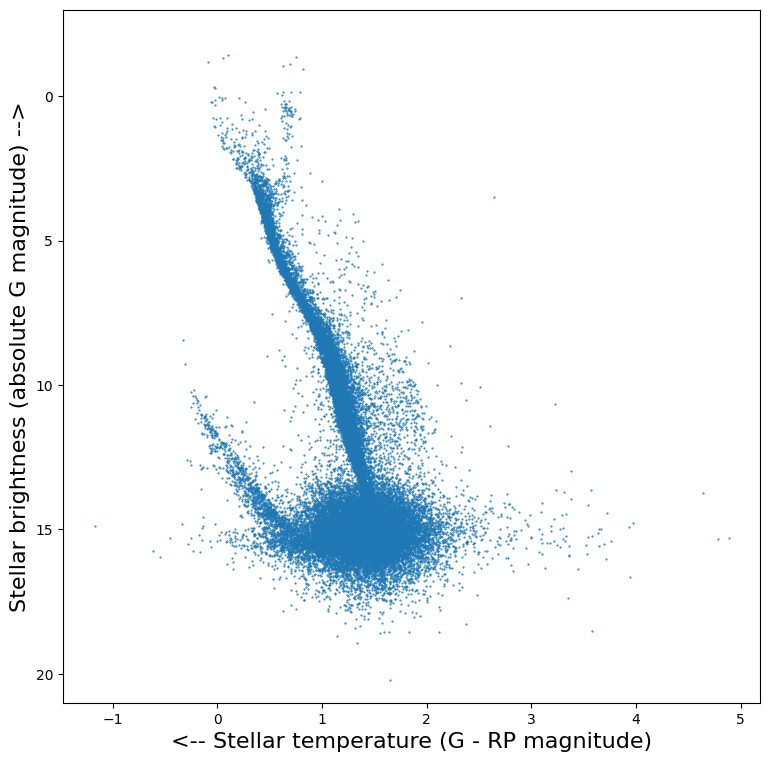

In [3]:
# plot an observational Hertzsprung-Russell diagram (aka colour / absolute magnitude diagram) for the unclassified sample to show the problem,
# include the photometric consistency filter to show the problem is astrometric in addition to photometric
unclassified_camd_df = spark.sql('SELECT phot_g_mean_mag + 5.0*LOG10(parallax/100.0) AS m_g, g_rp FROM raw_sources WHERE parallax > +8.0' + quick_plot_filter)# + photometric_consistency_filter)

import matplotlib.pyplot as plot
plot.figure(0, figsize = (9.0, 9.0))
x = list(unclassified_camd_df.select('g_rp').toPandas()['g_rp'])
y = list(unclassified_camd_df.select('m_g').toPandas()['m_g'])
plot.scatter(x, y, marker = '.', s = 1)
plot.ylim(21.0, -3.0)
plot.ylabel('Stellar brightness (absolute G magnitude) -->', fontsize = 16)
plot.xlabel('<-- Stellar temperature (G - RP magnitude)', fontsize = 16)
plot.show()

<br>The problem: while we see astrophysically interesting locii in the colour / absolute-magnitude diagram in the previous cell, the lower right (cool, low temperature) regime is dominated by systematic errors (not random uncertainties - the data should be equally precise in all parts of this data space) that create contamination in the raw sample. We wish to clean the sample to obtain high reliability

* without compromising completeness;
* utilising astrometric quality features in the raw catalogue for a volume-complete sample;
* and efficiently; 

i.e. without endless iterations of manual, subjective, axis-parallel and arbitrary cuts on available catalogue attributes. A neat solution to this is to use supervised ML. In the Gaia EDR3 performance verification paper "Gaia Catalogue of Nearby Stars" (Smart, Sarro, Rybicki, et al. 2020) we use a Random Forest of decision trees on selected features having first defined a training set based on the data itself. 

An 8 mas training set of "good" examples is "cleaned" of highly probable spurious sources using <i>independent</i> photometric criteria, i.e. we require consistency of optical colours. The "bad" examples are selected having (unphysical) parallax < -8 mas, i.e. using parallax measurements that are formally highly significant, yet obviously spurious. Under the assumption of normally distributed uncertainties on the parallax measurements, this bad sample should be representative of the corresponding spurious measurements having parallax > 8 mas that contaminate the parallax-selected sample and, in particular, create the contamination illustrated in the plot above.


In [4]:
# good training data: first define rough positional cuts to exclude crowded regions at low Galactic latitude, and inside the Large and Small Magellanic Clouds (Luri et al. 2020):
low_galactic_latitude_filter = ' AND ABS(b) > 25.0'
smc_filter = ' AND (dec < -80.0 OR dec > -65.0 OR (ra < 350.0 AND ra > +40.0))'
lmc_filter = ' AND (dec < -80.0 OR dec > -55.0 OR ra < 40.0 OR ra > 120.0)'
all_good_training_df = spark.sql('SELECT 1 AS label, ' + features_select_string + ' FROM raw_sources WHERE parallax > + 8.0 AND ABS(b) > 25.0' + photometric_consistency_filter + quick_filter + low_galactic_latitude_filter + smc_filter + lmc_filter)
good_training_rows = all_good_training_df.count()
print('Good training data size: %d rows'%(good_training_rows))

# bad training data: negative parallaxes: N.B. make a selection exactly the same size as the good training set based on size of smaller (good) data set and count of all available bads
maximal_bad_ast_count = spark.sql('SELECT source_id FROM raw_sources WHERE parallax < -8.0').count()
filter_factor = int(maximal_bad_ast_count / good_training_rows)
all_bad_training_df = spark.sql('SELECT 0 AS label, ' + features_select_string + ' FROM raw_sources WHERE  parallax < -8.0 AND MOD(random_index, %d) = 0'%(filter_factor) + ' ORDER BY random_index LIMIT %d'%(good_training_rows))
all_bad_training_data_count = all_bad_training_df.count()
print ('Bad  training data size: %d rows'%(all_bad_training_data_count))

Good training data size: 250283 rows


Bad  training data size: 250283 rows


In [5]:
# define training (67%) and test (33%) sample splits (seeded randomness for repeatability)
good_67pc, good_33pc = all_good_training_df.randomSplit([0.67, 0.33], 42)
bad_67pc, bad_33pc = all_bad_training_df.randomSplit([0.67, 0.33], 42)

# transform to labelled feature vectors (0.0 = bad, 1.0 = good, as conveniently already defined in previous projections above)

# Annotate and transform appropriate to the input required by the classifier's API.
# Need a dataframe with labels and features: use vector assembler. 
from pyspark.ml.feature import VectorAssembler
ignore = ['label',]
assembler = VectorAssembler(inputCols=[x for x in good_67pc.columns if x not in ignore], outputCol='features')

# training sets
good_training_df = assembler.transform(good_67pc).drop(*astrometric_features)
bad_training_df = assembler.transform(bad_67pc).drop(*astrometric_features)
# ... N.B. the original individual feature columns are dropped to save memory (since they are duplicated into the resulting feature vector).

# testing sets
good_testing_df = assembler.transform(good_33pc).drop(*astrometric_features)
bad_testing_df = assembler.transform(bad_33pc).drop(*astrometric_features)

# concatenate the training set into a single dataframe
training_df = good_training_df.union(bad_training_df)
#training_df.show()

In [ ]:
# This cell does the business, given the data and training sets. Follows the example Python code at 
# https://archive.apache.org/dist/spark/docs/3.5.2/api/python/reference/api/pyspark.ml.classification.RandomForestClassifier.html

from pyspark.ml.classification import RandomForestClassifier

# instantiate a trained RF classifier, seeded for repeatability at this stage:
rf = RandomForestClassifier(featureSubsetStrategy = 'sqrt', featuresCol = 'features', labelCol = 'label', numTrees = 500, impurity = 'gini', seed=42)
model = rf.fit(training_df)

In [7]:
# in case of any problems in the previous cell, check the features for nulls (there should be none, but if an exception "Consider removing nulls ..." is thrown):
#for feature in astrometric_features: print (spark.sql('SELECT COUNT(*) AS ' + feature + '_nulls FROM raw_sources WHERE ' + feature + ' IS NULL').show())

In [8]:
# classify based on the above trained model
good_test_results = model.transform(good_testing_df)
bad_test_results = model.transform(bad_testing_df)

#good_test_results.show()

In [9]:
# test results numerical output

# count up
from collections import Counter
positives = Counter(list(good_test_results.select('prediction').toPandas()['prediction']))
negatives = Counter(list(bad_test_results.select('prediction').toPandas()['prediction']))

# Confusion matrix (after GCNS paper, Table 1):
true_positives = positives[1.0]
false_positives = positives[0.0]
true_negatives = negatives[0.0]
false_negatives = negatives[1.0]
print('   |%7d%7d'%(1,2))
print('------------------------------')
print(' 1 |%7d%7d'%(true_positives, false_positives))
print(' 2 |%7d%7d'%(false_negatives, true_negatives))
print()

# Misclassification fraction: cf. GCNS paper which quotes 0.1%
num_misclassified = false_positives + false_negatives
total_num_in_test = true_positives + true_negatives + num_misclassified
misclassified_pc = 100.0 * float(num_misclassified) / float(total_num_in_test)
print('Misclassifications for the test set: %.2f %%'%(misclassified_pc))

#  10% EDR3 sample, 100 trees: 0.44% misclassifications
# 100%              500      : 0.38% (in 15min 57sec)

   |      1      2
------------------------------
 1 |  82406    527
 2 |     21  82578

Misclassifications for the test set: 0.33 %


In [10]:
import numpy

# examine relative importance of features wrt Appendix A.1 of the GCNS paper
feature_relative_importance = model.featureImportances.toArray()
sort_order = numpy.argsort(feature_relative_importance)
for idx in range(len(astrometric_features) - 1, 0, -1): 
    print('%30s  :  %f'%(astrometric_features[sort_order[idx]], feature_relative_importance[sort_order[idx]]))

                parallax_error  :  0.259764
       astrometric_sigma5d_max  :  0.184238
                    pmra_error  :  0.164096
           parallax_over_error  :  0.146132
                   pmdec_error  :  0.079586
      astrometric_excess_noise  :  0.068600
    ipd_gof_harmonic_amplitude  :  0.049202
           ipd_frac_multi_peak  :  0.013856
                          ruwe  :  0.011876
       visibility_periods_used  :  0.008353
                         pmdec  :  0.005846
            astrometric_gof_al  :  0.003023
                          pmra  :  0.002307
              ipd_frac_odd_win  :  0.001439
  astrometric_excess_noise_sig  :  0.001049


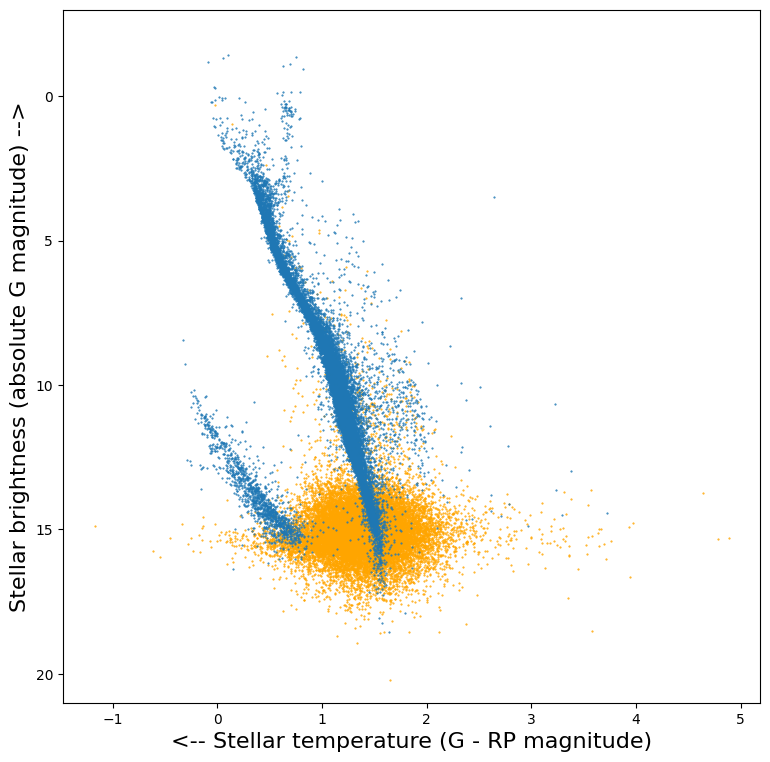

In [11]:
# cleaned up CAMD (observational HRD) employing the classifications

# get the complete unclassified sample:
unclassified_sample_df = spark.sql('SELECT * FROM raw_sources WHERE parallax > +8.0' + quick_filter)

# required features subset for the classification model
assembler = VectorAssembler(inputCols=[x for x in unclassified_sample_df.columns if x in astrometric_features], outputCol='features')
df_to_classify = assembler.transform(unclassified_sample_df)
all_classifications = model.transform(df_to_classify)
#all_classifications.show()

# the above are rather expensive operationa so cache the results for all later plotting cells:
all_classifications_cached = all_classifications.cache()

# register as SQL-queryable:
all_classifications_cached.createOrReplaceTempView('classified_sources')

# select on binary classification for a quick check:
good_sources_df = spark.sql('SELECT phot_g_mean_mag + 5.0*LOG10(parallax/100.0) AS m_g, g_rp, ra, dec FROM classified_sources WHERE prediction=1.0' + quick_plot_filter)
bad_sources_df =  spark.sql('SELECT phot_g_mean_mag + 5.0*LOG10(parallax/100.0) AS m_g, g_rp, ra, dec FROM classified_sources WHERE prediction=0.0' + quick_plot_filter)

import matplotlib.pyplot as plot
plot.figure(1, figsize = (9.0, 9.0))
x = list(bad_sources_df.select('g_rp').toPandas()['g_rp'])
y = list(bad_sources_df.select('m_g').toPandas()['m_g'])
plot.scatter(x, y, marker = '.', s = 1, c = 'orange')
x = list(good_sources_df.select('g_rp').toPandas()['g_rp'])
y = list(good_sources_df.select('m_g').toPandas()['m_g'])
plot.scatter(x, y, marker = '.', s = 1)
plot.ylim(21.0, -3.0)
plot.ylabel('Stellar brightness (absolute G magnitude) -->', fontsize = 16)
plot.xlabel('<-- Stellar temperature (G - RP magnitude)', fontsize = 16)
plot.show()

Text(0, 0.5, 'N')

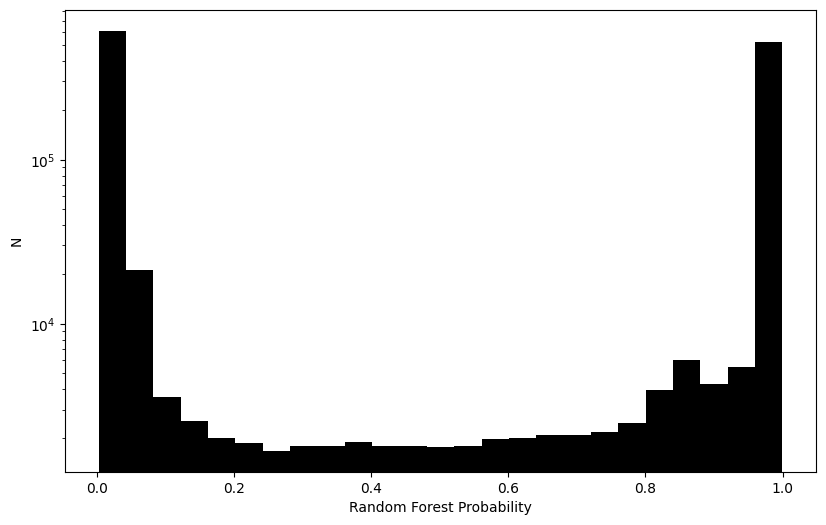

In [12]:
# histogram of the classification probabilities: cf. GCNS paper Figure 3

import matplotlib.pyplot as plot
plot.figure(1, figsize = (9.7, 6.0))
plot.yscale('log')
x = list(all_classifications_cached.select('probability').toPandas()['probability'])
# the probability column values are actually rich objects (DenseVector) containing p and 1-p for our two classes
# so pick one to plot (without the following line, both probabilities are counted up resulting in a symmetrical plot!)
x = [i.values[1] for i in x]
plot.hist(x, bins=25, color='black')
plot.xlabel('Random Forest Probability')
plot.ylabel('N')

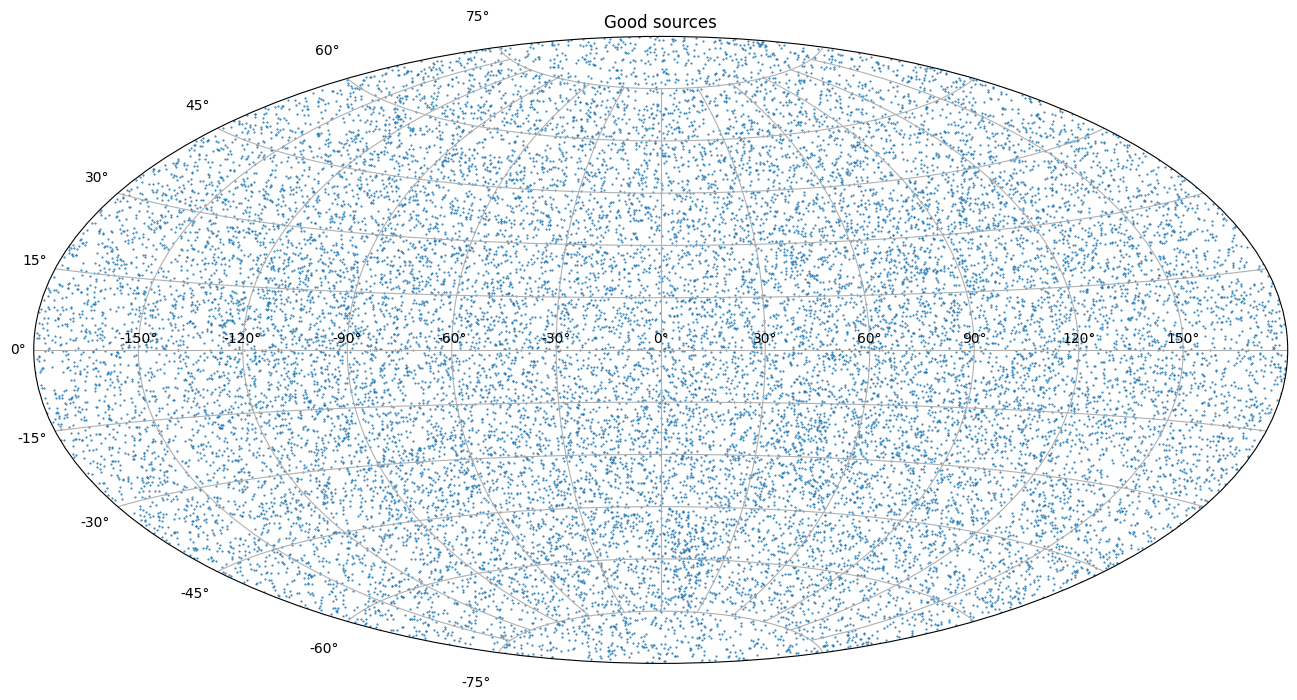

In [13]:
# cf. GCNS paper Figure 1 panels, sky distribution of good/bad sources:

import math

plot.figure(2, figsize = (16.18, 10.0))
plot.subplot(111, projection='aitoff')
plot.grid(True)
x = list((good_sources_df.select('ra').toPandas()['ra'] - 180.0) * math.pi / 180.0)
y = list(good_sources_df.select('dec').toPandas()['dec'] * math.pi / 180.0)
plot.title('Good sources')
plot.scatter(x, y, marker = '.', s = 1)

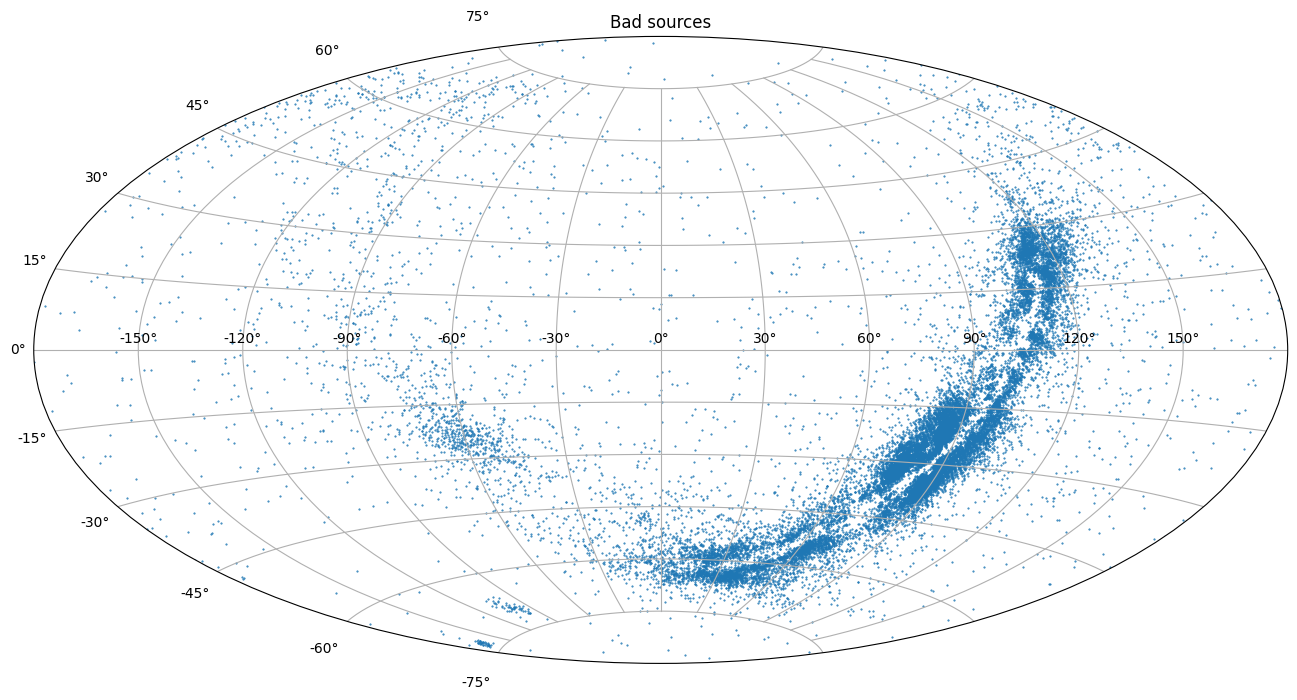

In [14]:
plot.figure(3, figsize = (16.18, 10.0))
plot.subplot(111, projection='aitoff')
plot.grid(True)
x = list((bad_sources_df.select('ra').toPandas()['ra'] - 180.0) * math.pi / 180.0)
y = list(bad_sources_df.select('dec').toPandas()['dec'] * math.pi / 180.0)
plot.title('Bad sources')
plot.scatter(x, y, marker = '.', s = 1)

* [Gaia Early Data Release 3: The Gaia Catalogue of Nearby Stars (R.Smart et al. 2021)](https://www.aanda.org/articles/aa/full_html/2021/05/aa39498-20/aa39498-20.html "Smart et al., A&A, 649 (2021) A6")
* [Apache Spark ML API](https://spark.apache.org/docs/3.5.2/ml-statistics.html "Spark 2.4.7 ML API")
* [A classifier for spurious astrometric solutions in Gaia EDR3 (J.Rybizki et al. 2021)](https://arxiv.org/abs/2101.11641 "astro-ph/2101.11641")
* [Python matplotlib plotting library](https://matplotlib.org)
